# PathSnap — Exploratory Data Analysis

Owner: **P1**. Executed top to bottom so the committed outputs are real, not stale.

Everything here is generated from the raw files in `data/raw/`. Figures are written to
`reports/figures/` so they can be lifted into the technical report.

Run with: `jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb`

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathsnap.config import TRAIN_DIR, STUDENT_TEST_DIR, RESULTS_DIR, PROJECT_ROOT
from pathsnap.io.loaders import discover_trips, load_trip
from pathsnap.geo.distance import haversine_m
from pathsnap.labels import assign_reference_arcs

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("project root:", PROJECT_ROOT)
print("figures    :", FIG_DIR)

project root: C:\Users\kisha\Documents\ML\Hackathon_ML\pathsnap
figures    : C:\Users\kisha\Documents\ML\Hackathon_ML\pathsnap\reports\figures


## 1. Dataset inventory

The brief asks for trip counts, per-trip observation counts, file availability, node/arc
counts and reference-route availability. This builds that table from the raw files.

In [2]:
def path_length_m(lon, lat):
    return float(haversine_m(lon[:-1], lat[:-1], lon[1:], lat[1:]).sum())


rows = []
for partition, root in (("train", TRAIN_DIR), ("student_test", STUDENT_TEST_DIR)):
    if not root.is_dir():
        continue
    for trip_dir in discover_trips(root):
        t = load_trip(trip_dir)
        dt = t.track.time_deltas()
        net_len = t.network.arc_lengths_m()
        rows.append({
            "partition": partition,
            "trip_id": t.trip_id,
            "n_obs": len(t.track),
            "duration_s": float(t.track.timestamp[-1] - t.track.timestamp[0]),
            "dt_median_s": float(np.median(dt)) if len(dt) else np.nan,
            "dt_max_s": float(dt.max()) if len(dt) else np.nan,
            "n_nodes": t.network.n_nodes,
            "n_arcs": t.network.n_arcs,
            "arc_len_median_m": float(np.median(net_len)),
            "n_route_arcs": 0 if t.route is None else int(len(t.route)),
            "gps_path_km": path_length_m(t.track.lon, t.track.lat) / 1000.0,
            "route_km": 0.0 if t.route is None else float(net_len[t.route].sum()) / 1000.0,
            "lon_min": float(t.track.lon.min()), "lon_max": float(t.track.lon.max()),
            "lat_min": float(t.track.lat.min()), "lat_max": float(t.track.lat.max()),
        })

inv = pd.DataFrame(rows)
inv["route_coverage"] = inv["route_km"] / inv["gps_path_km"].replace(0, np.nan)
inv.to_csv(RESULTS_DIR / "dataset_inventory.csv", index=False)

summary = inv.groupby("partition").agg(
    trips=("trip_id", "count"),
    observations=("n_obs", "sum"),
    obs_median=("n_obs", "median"),
    obs_max=("n_obs", "max"),
    nodes=("n_nodes", "sum"),
    arcs=("n_arcs", "sum"),
    trips_with_route=("n_route_arcs", lambda s: int((s > 0).sum())),
)
summary

,trips,observations,obs_median,obs_max,nodes,arcs,trips_with_route
partition,,,,,,,
student_test,10,19160,1420.0,3958,90689,185041,10
train,80,208417,1529.0,19313,1933485,3876904,80


Surprising but correct: the trips are not all in the same city. A single trip is locally
coherent, but longitude spans -100 to +137 degrees across trips, which is why the
projection has to be anchored **per trip** and nothing may be normalised globally.

In [3]:
print(inv.groupby("partition")[["lon_min", "lon_max", "lat_min", "lat_max"]].agg(["min", "max"]))
print()
print("dt_median values:", sorted(inv["dt_median_s"].round(2).unique())[:5])
print("largest gap (h):", round(inv["dt_max_s"].max() / 3600, 1), "on trip", inv.loc[inv["dt_max_s"].idxmax(), "trip_id"])

                 lon_min                 lon_max                lat_min               lat_max           
                     min         max         min         max        min        max        min        max
partition                                                                                               
student_test  -93.424337   77.122052  -93.348525   77.271115  42.645529  61.639754  42.662443  61.699590
train        -100.418538  137.197657 -100.268049  137.237029 -34.640291  61.233324 -34.609083  61.267258

dt_median values: [np.float64(1.0)]
largest gap (h): 42.5 on trip 00000090


## 2. Trajectory sizes and sampling rate

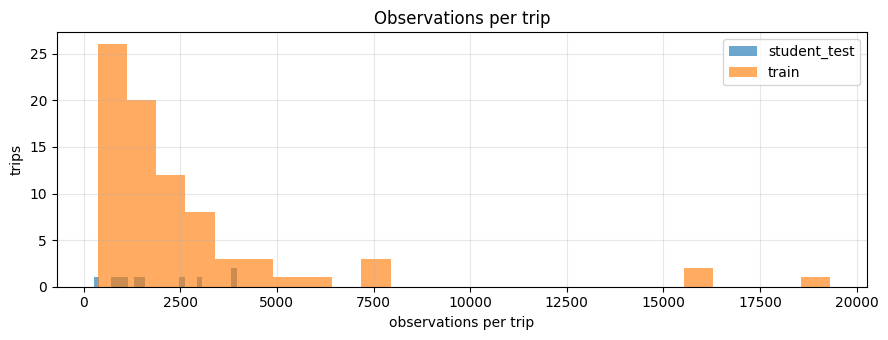

In [4]:
fig, ax = plt.subplots()
for part, sub in inv.groupby("partition"):
    ax.hist(sub["n_obs"], bins=25, alpha=0.65, label=part)
ax.set_xlabel("observations per trip")
ax.set_ylabel("trips")
ax.set_title("Observations per trip")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "obs_per_trip.png", dpi=130)
plt.show()

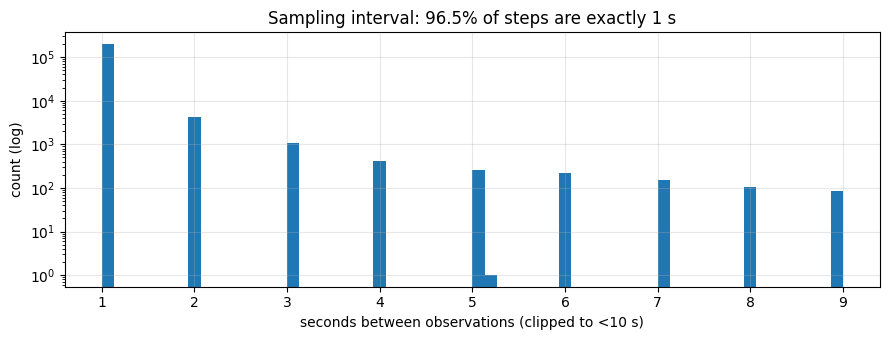

steps > 60 s : 69 (0.03%)
largest gap  : 153,064 s = 42.5 h


In [5]:
dt_all = []
for trip_dir in discover_trips(TRAIN_DIR):
    t = load_trip(trip_dir)
    dt_all.append(t.track.time_deltas())
dt_all = np.concatenate(dt_all)
dt_clipped = dt_all[dt_all < 10]

fig, ax = plt.subplots()
ax.hist(dt_clipped, bins=60)
ax.set_yscale("log")
ax.set_xlabel("seconds between observations (clipped to <10 s)")
ax.set_ylabel("count (log)")
ax.set_title(f"Sampling interval: {(dt_all == 1).mean():.1%} of steps are exactly 1 s")
fig.tight_layout()
fig.savefig(FIG_DIR / "dt_distribution.png", dpi=130)
plt.show()

print(f"steps > 60 s : {(dt_all > 60).sum():,} ({(dt_all > 60).mean():.2%})")
print(f"largest gap  : {dt_all.max():,.0f} s = {dt_all.max()/3600:.1f} h")

The gap distribution is why the HMM decoder cannot assume `dt ≈ 1 s`: a 42-hour gap
exists in the training data. Speed features are clipped, and the decoder has to decide
what to do at a discontinuity.

## 3. Road-network geometry

This section justifies the candidate-generation design: with networks up to 307k arcs,
comparing every observation against every arc is infeasible.

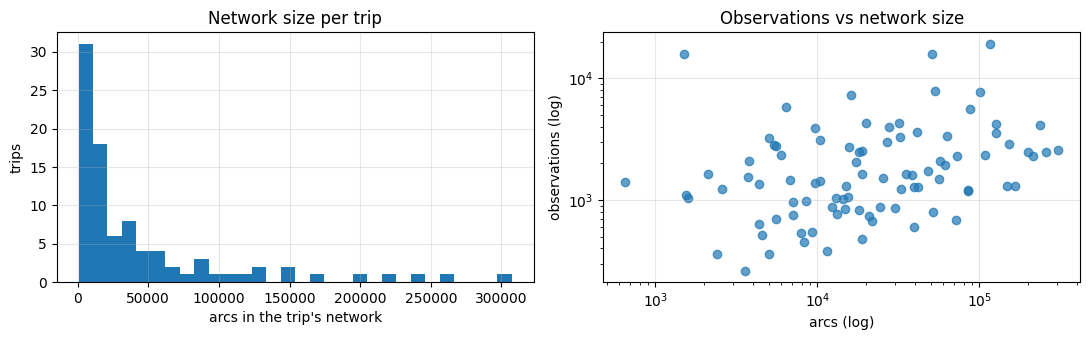

worst case: trip 00000013  arcs=307,392  obs=2,580  brute-force pairs=793,071,360


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
ax.hist(inv["n_arcs"], bins=30)
ax.set_xlabel("arcs in the trip's network")
ax.set_ylabel("trips")
ax.set_title("Network size per trip")

ax = axes[1]
ax.scatter(inv["n_arcs"], inv["n_obs"], alpha=0.7)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("arcs (log)"); ax.set_ylabel("observations (log)")
ax.set_title("Observations vs network size")
fig.tight_layout()
fig.savefig(FIG_DIR / "network_size.png", dpi=130)
plt.show()

worst = inv.loc[inv["n_arcs"].idxmax()]
print(f"worst case: trip {worst.trip_id}  arcs={worst.n_arcs:,}  obs={worst.n_obs:,}  "
      f"brute-force pairs={worst.n_arcs * worst.n_obs:,}")

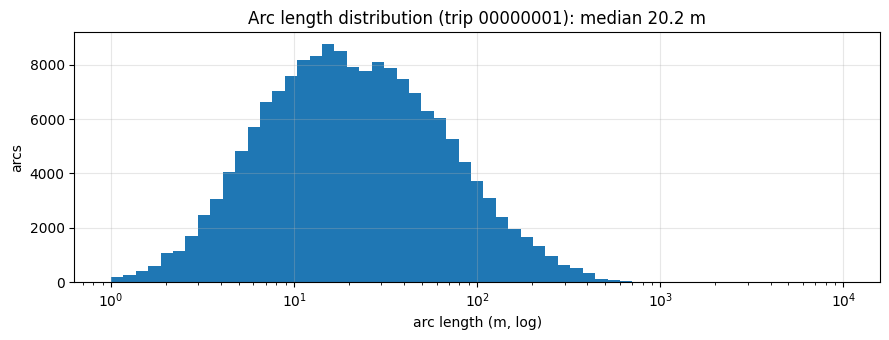

arcs < 50 m : 76.8%
arcs > 500 m: 0.08%
longest arc : 1,106 m


In [7]:
trip = load_trip(TRAIN_DIR / "00000001")
arc_len = trip.network.arc_lengths_m()

fig, ax = plt.subplots()
ax.hist(arc_len, bins=np.logspace(0, 4, 60))
ax.set_xscale("log")
ax.set_xlabel("arc length (m, log)")
ax.set_ylabel("arcs")
ax.set_title(f"Arc length distribution (trip 00000001): median {np.median(arc_len):.1f} m")
fig.tight_layout()
fig.savefig(FIG_DIR / "arc_lengths.png", dpi=130)
plt.show()

print(f"arcs < 50 m : {(arc_len < 50).mean():.1%}")
print(f"arcs > 500 m: {(arc_len > 500).mean():.2%}")
print(f"longest arc : {arc_len.max():,.0f} m")

Because 73% of arcs are shorter than 50 m but a few are kilometres long, candidate
generation bins arcs by bounding box and evaluates long arcs separately. That keeps the
search exact — no true candidate can be missed — while staying fast.

## 4. Reference-route coverage and label quality

The supplied `.route` is the ground truth for the travelled path. It is not guaranteed to
cover the whole trajectory. Comparing its length with the distance the GPS actually
travelled exposes trips where it plainly does not.

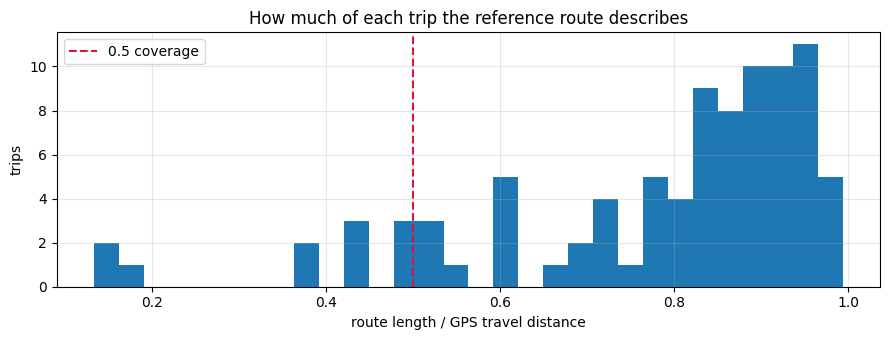

trips with route coverage < 0.5: 11


,partition,trip_id,n_obs,gps_path_km,route_km,route_coverage
26,train,00000033,5844,47.833,6.379,0.133
1,train,00000002,7243,55.872,7.963,0.143
44,train,00000054,19313,169.254,31.363,0.185
6,train,00000008,3093,25.044,9.349,0.373
16,train,00000021,15783,128.789,48.590,0.377
67,train,00000084,16031,136.807,58.392,0.427
88,student_test,00000077,3911,36.294,15.980,0.440
7,train,00000010,2711,25.815,11.404,0.442
65,train,00000082,4268,44.049,21.167,0.481
60,train,00000075,1628,13.379,6.435,0.481


In [8]:
fig, ax = plt.subplots()
ax.hist(inv["route_coverage"].dropna(), bins=30)
ax.axvline(0.5, color="crimson", linestyle="--", label="0.5 coverage")
ax.set_xlabel("route length / GPS travel distance")
ax.set_ylabel("trips")
ax.set_title("How much of each trip the reference route describes")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "route_coverage.png", dpi=130)
plt.show()

low = inv[inv["route_coverage"] < 0.5][["partition", "trip_id", "n_obs", "gps_path_km", "route_km", "route_coverage"]]
print(f"trips with route coverage < 0.5: {len(low)}")
low.sort_values("route_coverage").round(3)

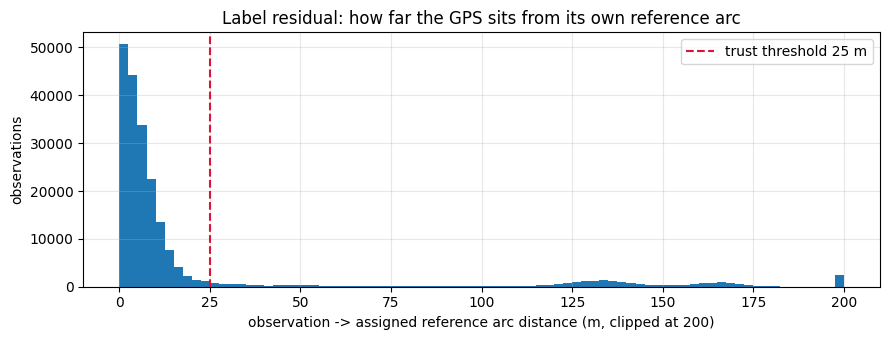

observations within 10 m of their reference arc: 72.6%
observations within 25 m of their reference arc: 87.1%
observations within 50 m of their reference arc: 89.2%
total observations: 208,417


In [9]:
residuals = []
for trip_dir in discover_trips(TRAIN_DIR):
    t = load_trip(trip_dir)
    ref = assign_reference_arcs(t)
    residuals.append(pd.DataFrame({
        "trip_id": t.trip_id, "residual_m": ref.dist_per_obs, "backwards": ref.n_backwards,
    }))
res = pd.concat(residuals, ignore_index=True)

fig, ax = plt.subplots()
ax.hist(np.clip(res["residual_m"], 0, 200), bins=80)
ax.axvline(25, color="crimson", linestyle="--", label="trust threshold 25 m")
ax.set_xlabel("observation -> assigned reference arc distance (m, clipped at 200)")
ax.set_ylabel("observations")
ax.set_title("Label residual: how far the GPS sits from its own reference arc")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "label_residual.png", dpi=130)
plt.show()

for thr in (10, 25, 50):
    print(f"observations within {thr:>2} m of their reference arc: {(res.residual_m <= thr).mean():.1%}")
print(f"total observations: {len(res):,}")

An observation 140 m from its "reference" arc is not a hard example — the label is
wrong, because the route does not cover that part of the drive. Those observations are
excluded from fitting and scoring via the label-trust filter (residual ≤ 25 m). They are
still predicted on at inference time.

## 5. Candidate quality (the gate on every downstream model)

In [10]:
quality = json.loads((RESULTS_DIR / "candidate_quality.json").read_text())
pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "trips_worst_10"} for k, v in quality.items()}).T

,n_trips,n_observations,n_candidate_rows,candidates_per_observation,candidate_miss_rate_mean,candidate_miss_rate_median,candidate_miss_rate_p90,candidate_miss_rate_worst,trusted_fraction,trust_residual_m
train,80.0,208417.0,1453943.0,6.976,0.0341,0.0073,0.0420,0.8620,0.9300,25.0
student_test,10.0,19160.0,148752.0,7.764,0.0117,0.0071,0.0264,0.0322,0.9849,25.0


In [11]:
worst = pd.DataFrame(quality["train"]["trips_worst_10"])
worst

,trip_id,miss_rate,trusted_fraction,n_obs
0,00000054,0.8620,0.3196,19313
1,00000033,0.6685,0.3666,5844
2,00000072,0.1342,0.9983,969
3,00000002,0.1323,0.8912,7243
4,00000061,0.0615,0.9441,1430
5,00000043,0.0495,0.8473,2322
6,00000093,0.0471,0.9520,1211
7,00000090,0.0448,1.0000,536
8,00000058,0.0417,1.0000,599
9,00000008,0.0372,0.9405,3093


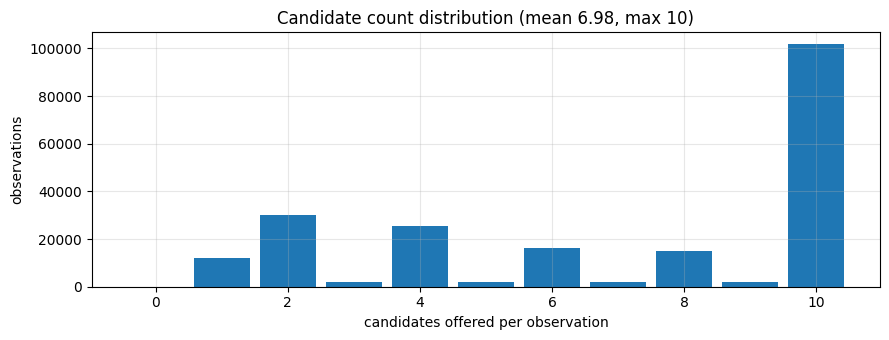

observations with zero candidates: 0


In [12]:
from pathsnap.features.dataset import load_trip_features

cand_per_obs = []
for trip_dir in discover_trips(TRAIN_DIR):
    tf = load_trip_features(trip_dir.name, "train")
    counts = np.bincount(tf.obs_idx, minlength=tf.n_obs)
    cand_per_obs.append(counts)
cand_per_obs = np.concatenate(cand_per_obs)

fig, ax = plt.subplots()
ax.hist(cand_per_obs, bins=range(0, 12), align="left", rwidth=0.85)
ax.set_xlabel("candidates offered per observation")
ax.set_ylabel("observations")
ax.set_title(f"Candidate count distribution (mean {cand_per_obs.mean():.2f}, max {cand_per_obs.max()})")
fig.tight_layout()
fig.savefig(FIG_DIR / "candidates_per_obs.png", dpi=130)
plt.show()

print(f"observations with zero candidates: {(cand_per_obs == 0).sum()}")

## 6. Folium maps

Mandatory deliverable. Each map has the raw GPS, the road network and (where available)
the reference route as separate toggleable layers with a legend.

In [13]:
from pathsnap.viz.folium_maps import build_eda_map

map_dir = PROJECT_ROOT / "reports" / "maps"
paths = []
for trip_id in ["00000003", "00000013"]:
    t = load_trip(TRAIN_DIR / trip_id)
    paths.append(build_eda_map(t, map_dir / f"eda_{trip_id}.html"))
    print("wrote", paths[-1].relative_to(PROJECT_ROOT), f"{paths[-1].stat().st_size/1024:.0f} KB")

wrote reports\maps\eda_00000003.html 604 KB


wrote reports\maps\eda_00000013.html 1569 KB


In [14]:
from IPython.display import IFrame
IFrame(src="../reports/maps/eda_00000003.html", width="100%", height=460)

## 7. Findings carried into the design

1. **Trips are in different cities** → per-trip projection; no global normalisation.
2. **Sampling is 1 Hz but not uniformly** → a 42-hour gap exists; speed features are
   clipped and the decoder must handle discontinuities explicitly.
3. **Networks are large (up to 307k arcs)** → candidate generation needs a spatial index;
   brute force would be ~3.9e9 segment tests for one trip.
4. **Reference routes are sometimes truncated** (10 trips below 50% coverage) → labels
   from them are wrong; a residual ≤ 25 m trust filter keeps 93% of training rows.
5. **Candidate miss rate** is 3.41% over all labels but 1.22% on trusted labels — the gap
   is entirely those truncated-route trips, and both numbers must be reported.
6. **Arcs are short** (median ~25 m) but a few exceed 2 km → bbox binning plus a separate
   long-arc list keeps candidate generation exact.